# NOTE
I am saving the files on a local folder. Please change PROJECT = "/Users/aklantaborah/Desktop/RTProject" ( to some local folder ) before running the code


In [1]:
import os, sys, warnings, itertools, time
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from scipy import stats
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform

warnings.filterwarnings("ignore")
t_start = time.time()

# ---- paths (change DATA_PATH if your csv is somewhere else) ----
PROJECT = "/Users/aklantaborah/Desktop/RTProject2"
OUT = os.environ.get("RT_OUT", os.path.join(PROJECT, "RTimages"))
os.makedirs(OUT, exist_ok=True)
candidates = [os.environ.get("RT_DATA", ""),
              os.path.join(PROJECT, "energydata_complete.csv"),
              "energydata_complete.csv",
              os.path.expanduser("~/Desktop/energydata_complete.csv"),
              os.path.expanduser("~/Downloads/energydata_complete.csv")]
DATA_PATH = next((p for p in candidates if p and os.path.exists(p)), None)
if DATA_PATH is None:
    raise FileNotFoundError("energydata_complete.csv not found. Put it in " + PROJECT +
                            " or set DATA_PATH by hand in this cell.")

plt.rcParams.update({"figure.dpi": 90, "savefig.dpi": 200, "font.size": 9,
                     "axes.titlesize": 10, "axes.grid": True, "grid.alpha": 0.25})

LOG = os.path.join(OUT, "results_log.txt")
open(LOG, "w").close()

def log(*a):
    s = " ".join(str(x) for x in a)
    print(s)
    with open(LOG, "a") as f:
        f.write(s + "\n")

def save_fig(fig, name):
    fig.tight_layout()
    fig.savefig(os.path.join(OUT, name), bbox_inches="tight")
    plt.show()
    plt.close(fig)

def save_tab(df_, name, index=True):
    df_.to_csv(os.path.join(OUT, name), index=index)

log("data file:", DATA_PATH)
log("output folder:", OUT)

data file: energydata_complete.csv
output folder: /Users/aklantaborah/Desktop/RTProject2/RTimages


## Helper functions
Everything here is written with numpy.
Durbin-Watson (large sample normal version),Breusch-Pagan, Cook-Weisberg, Q-Q plot, ACF/PACF, Box-Cox profile likelihood,
and the model selection criteria (adjusted R2, Cp, AIC, BIC, LOOCV).

In [2]:
def ols(X, y):
    """OLS with intercept. X is n x p (no intercept column). Returns a dict."""
    X = np.asarray(X, float); y = np.asarray(y, float)
    n, p = X.shape
    A = np.column_stack([np.ones(n), X])
    AtAi = np.linalg.pinv(A.T @ A)
    beta = AtAi @ A.T @ y
    fit = A @ beta
    e = y - fit
    rss = e @ e
    sst = ((y - y.mean()) ** 2).sum()
    dof = n - p - 1
    s2 = rss / dof
    se = np.sqrt(np.diag(AtAi) * s2)
    t = beta / se
    pv = 2 * stats.t.sf(np.abs(t), dof)
    r2 = 1 - rss / sst
    adj = 1 - (1 - r2) * (n - 1) / dof
    F = ((sst - rss) / p) / s2 if p > 0 else np.nan
    h = np.einsum("ij,jk,ik->i", A, AtAi, A)
    return dict(beta=beta, se=se, t=t, p=pv, resid=e, fitted=fit, rss=rss, sst=sst, s2=s2,
                dof=dof, r2=r2, adj=adj, F=F, pF=stats.f.sf(F, p, dof) if p > 0 else np.nan,
                h=h, n=n, k=p, A=A, AtAi=AtAi, sigma=np.sqrt(s2))

def predict(beta, X):
    X = np.asarray(X, float)
    return beta[0] + X @ beta[1:]

def std_resid(m):
    """standardized (internally studentized) residuals from class notes"""
    return m["resid"] / (m["sigma"] * np.sqrt(1 - m["h"]))

def rmse(a, p): return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(p)) ** 2)))
def mae(a, p): return float(np.mean(np.abs(np.asarray(a) - np.asarray(p))))
def r2_oos(a, p, bench):
    a = np.asarray(a); return float(1 - np.sum((a - p) ** 2) / np.sum((a - bench) ** 2))

def skew(x): x = np.asarray(x); return float(np.mean((x - x.mean()) ** 3) / x.std() ** 3)
def kurt(x): x = np.asarray(x); return float(np.mean((x - x.mean()) ** 4) / x.std() ** 4)

# ---- autocorrelation tools ----
def acf(x, nlags):
    x = np.asarray(x, float); x = x - x.mean(); d = x @ x
    return np.array([1.0] + [(x[k:] @ x[:-k]) / d for k in range(1, nlags + 1)])

def pacf(x, nlags):
    """Durbin-Levinson on the sample ACF (same idea as the PACF in class notes)"""
    r = acf(x, nlags); out = [1.0]; phi = np.zeros((nlags + 1, nlags + 1))
    phi[1, 1] = r[1]; out.append(r[1])
    for k in range(2, nlags + 1):
        num = r[k] - sum(phi[k - 1, j] * r[k - j] for j in range(1, k))
        den = 1 - sum(phi[k - 1, j] * r[j] for j in range(1, k))
        phi[k, k] = num / den
        for j in range(1, k):
            phi[k, j] = phi[k - 1, j] - phi[k, k] * phi[k - 1, k - j]
        out.append(phi[k, k])
    return np.array(out)

def plot_acf_ax(ax, x, nlags, title):
    r = acf(x, nlags); n = len(x)
    ax.vlines(range(1, nlags + 1), 0, r[1:], color="k", lw=0.8)
    ax.axhline(0, color="k", lw=0.6)
    ax.axhline(1.96 / np.sqrt(n), color="b", ls="--", lw=0.8)
    ax.axhline(-1.96 / np.sqrt(n), color="b", ls="--", lw=0.8)
    ax.set_title(title); ax.set_xlabel("lag"); ax.set_ylabel("ACF"); ax.xaxis.set_major_locator(MaxNLocator(integer=True))

def plot_pacf_ax(ax, x, nlags, title):
    r = pacf(x, nlags); n = len(x)
    ax.vlines(range(1, nlags + 1), 0, r[1:], color="k", lw=0.8)
    ax.axhline(0, color="k", lw=0.6)
    ax.axhline(1.96 / np.sqrt(n), color="b", ls="--", lw=0.8)
    ax.axhline(-1.96 / np.sqrt(n), color="b", ls="--", lw=0.8)
    ax.set_title(title); ax.set_xlabel("lag"); ax.set_ylabel("PACF"); ax.xaxis.set_major_locator(MaxNLocator(integer=True))

# ---- tests from class ----
def dw_test(e):
    """Durbin-Watson D and the large sample test: sqrt(T)*r1 ~ N(0,1) under H0"""
    e = np.asarray(e); D = np.sum(np.diff(e) ** 2) / np.sum(e ** 2)
    r1 = np.sum(e[1:] * e[:-1]) / np.sum(e ** 2)
    z = np.sqrt(len(e)) * r1
    return dict(D=float(D), r1=float(r1), z=float(z), p=float(2 * stats.norm.sf(abs(z))))

def bp_test(e, Z):
    """Breusch-Pagan as in class: V=e^2/sigma2_ML, regress V on Z, S0 = 0.5*ESS ~ chi2_k"""
    e = np.asarray(e); n = len(e); Z = np.asarray(Z, float).reshape(n, -1)
    V = e ** 2 / np.mean(e ** 2)
    Z1 = np.column_stack([np.ones(n), Z])
    b = np.linalg.lstsq(Z1, V, rcond=None)[0]
    S0 = 0.5 * np.sum((Z1 @ b - V.mean()) ** 2)
    k = Z1.shape[1] - 1
    return dict(S=float(S0), df=int(k), p=float(stats.chi2.sf(S0, k)))

def cw_test(e, fitted):
    """Cook-Weisberg as in class: same thing but regress V on the fitted values only (df=1)"""
    return bp_test(e, np.asarray(fitted).reshape(-1, 1))

def vif_table(X, names):
    X = np.asarray(X, float)
    if X.shape[1] == 1: return pd.Series([1.0], index=list(names))
    R = np.corrcoef(X, rowvar=False)
    return pd.Series(np.diag(np.linalg.inv(R)), index=names)

def cond_number(X):
    Z = (X - X.mean(0)) / X.std(0)
    s = np.linalg.svd(Z, compute_uv=False)
    return float(s.max() / s.min())

def trend_line(ax, x, y, nb=30, color="red"):
    """simple smoother: mean of y in quantile bins of x"""
    x = np.asarray(x); y = np.asarray(y)
    edges = np.quantile(x, np.linspace(0, 1, nb + 1))
    idx = np.clip(np.searchsorted(edges, x, side="right") - 1, 0, nb - 1)
    xs = [x[idx == i].mean() for i in range(nb) if (idx == i).sum() > 3]
    ys = [y[idx == i].mean() for i in range(nb) if (idx == i).sum() > 3]
    ax.plot(xs, ys, color=color, lw=1.5)

def qq_ax(ax, u, title):
    u = np.sort(np.asarray(u)); n = len(u)
    th = stats.norm.ppf((np.arange(1, n + 1) - 0.5) / n)
    ax.scatter(th, u, s=3, alpha=0.4, rasterized=True)
    lim = [min(th.min(), u.min()), max(th.max(), u.max())]
    ax.plot(lim, lim, "r--", lw=1)
    ax.set_title(title); ax.set_xlabel("N(0,1) quantiles"); ax.set_ylabel("standardized residuals")

def resid_panel(m, title, fname, acf_lags, index_label="time index"):
    """6 plots used in class: residual vs fitted, e^2 vs fitted, QQ, index plot, ACF, PACF"""
    e = m["resid"]; yh = m["fitted"]; u = std_resid(m)
    fig, ax = plt.subplots(2, 3, figsize=(11, 6.2))
    ax[0, 0].scatter(yh, e, s=3, alpha=0.35, rasterized=True); trend_line(ax[0, 0], yh, e)
    ax[0, 0].axhline(0, color="k", lw=0.7)
    ax[0, 0].set_title("residuals vs fitted"); ax[0, 0].set_xlabel("fitted"); ax[0, 0].set_ylabel("residual")
    ax[0, 1].scatter(yh, e ** 2, s=3, alpha=0.35, rasterized=True); trend_line(ax[0, 1], yh, e ** 2)
    ax[0, 1].set_title("squared residuals vs fitted"); ax[0, 1].set_xlabel("fitted"); ax[0, 1].set_ylabel("e^2")
    qq_ax(ax[0, 2], u, "normal Q-Q plot")
    ax[1, 0].plot(e, lw=0.5, color="k"); ax[1, 0].axhline(0, color="r", lw=0.7)
    ax[1, 0].set_title("residuals in time order"); ax[1, 0].set_xlabel(index_label); ax[1, 0].set_ylabel("residual")
    plot_acf_ax(ax[1, 1], e, acf_lags, "ACF of residuals")
    plot_pacf_ax(ax[1, 2], e, min(acf_lags, 30), "PACF of residuals")
    fig.suptitle(title, y=1.0, fontsize=11)
    save_fig(fig, fname)

def all_tests(m, Z):
    """DW, Breusch-Pagan (on Z) and Cook-Weisberg (on fitted) for a fitted ols dict"""
    d = dw_test(m["resid"]); b = bp_test(m["resid"], Z); c = cw_test(m["resid"], m["fitted"])
    return d, b, c

def show_tests(name, m, Z):
    d, b, c = all_tests(m, Z)
    log(f"[{name}] DW={d['D']:.3f}  lag1 r={d['r1']:.3f}  z={d['z']:.2f}  p={d['p']:.2e}")
    log(f"[{name}] Breusch-Pagan S={b['S']:.2f} (df={b['df']})  p={b['p']:.3g}")
    log(f"[{name}] Cook-Weisberg S={c['S']:.2f} (df=1)  p={c['p']:.3g}")
    log(f"[{name}] residual skewness={skew(m['resid']):.2f}  kurtosis={kurt(m['resid']):.2f}")
    return d, b, c

## 1. Data

In [3]:
df = pd.read_csv(DATA_PATH)
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)

log("\n==== 1. DATA ====")
log("rows, columns:", df.shape)
log("period:", df["date"].min(), "to", df["date"].max())
steps = df["date"].diff().dropna().value_counts()
log("gaps between rows:\n" + steps.to_string())
log("missing values:", int(df.isna().sum().sum()), " duplicated rows:", int(df.duplicated().sum()))
num = df.drop(columns="date")
log("constant columns:", list(num.columns[num.std() == 0]) or "none")

summ = pd.DataFrame({"mean": num.mean(), "sd": num.std(), "min": num.min(), "max": num.max(),
                     "n_unique": num.nunique(), "pct_zero": (num == 0).mean() * 100}).round(3)
save_tab(summ, "t01_data_summary.csv")
log(summ.to_string())

# ---- rv1, rv2: why we drop them ----
rv_rows = []
for v in ["rv1", "rv2"]:
    r, p = stats.pearsonr(df[v], df["Appliances"])
    rv_rows.append((v, r, p))
rv = pd.DataFrame(rv_rows, columns=["variable", "corr_with_Appliances", "p_value"])
save_tab(rv, "t02_rv_correlation.csv", index=False)
log("\nrv1, rv2 correlation with Appliances:\n" + rv.round(4).to_string(index=False))
log("rv1 and rv2 identical columns?", bool(np.allclose(df["rv1"], df["rv2"])))

COVS = [f"T{i}" for i in range(1, 10)] + [f"RH_{i}" for i in range(1, 10)] + \
       ["T_out", "Press_mm_hg", "RH_out", "Windspeed", "Visibility", "Tdewpoint", "lights"]
df = df[["date", "Appliances"] + COVS].copy()   # rv1, rv2 dropped here
df["day"] = df["date"].dt.date
df["hour"] = df["date"].dt.hour
log("number of covariates used:", len(COVS))

# ---- days: full and partial ----
cnt = df.groupby("day").size()
full_days = cnt[cnt == 144].index
log("calendar days:", len(cnt), " full days (144 readings):", len(full_days),
    " partial days:", {str(k): int(v) for k, v in cnt[cnt != 144].items()})


==== 1. DATA ====
rows, columns: (19735, 29)
period: 2016-01-11 17:00:00 to 2016-05-27 18:00:00
gaps between rows:
date
0 days 00:10:00    19734
missing values: 0  duplicated rows: 0
constant columns: none
                mean       sd      min       max  n_unique  pct_zero
Appliances    97.695  102.525   10.000  1080.000        92     0.000
lights         3.802    7.936    0.000    70.000         8    77.284
T1            21.687    1.606   16.790    26.260       722     0.000
RH_1          40.260    3.979   27.023    63.360      2547     0.000
T2            20.341    2.193   16.100    29.857      1650     0.000
RH_2          40.420    4.070   20.463    56.027      3376     0.000
T3            22.268    2.006   17.200    29.236      1426     0.000
RH_3          39.243    3.255   28.767    50.163      2618     0.000
T4            20.855    2.043   15.100    26.200      1390     0.000
RH_4          39.027    4.341   27.660    51.090      2987     0.000
T5            19.592    1.845   15

## 1b. EDA plots


==== 1b. EDA ====
Appliances: mean=97.69 median=60.0 sd=102.52 min=10 max=1080 skew=3.39 skew(log)=1.17
IQR rule: Q1=50 Q3=100 upper fence=175; share above fence = 10.8%


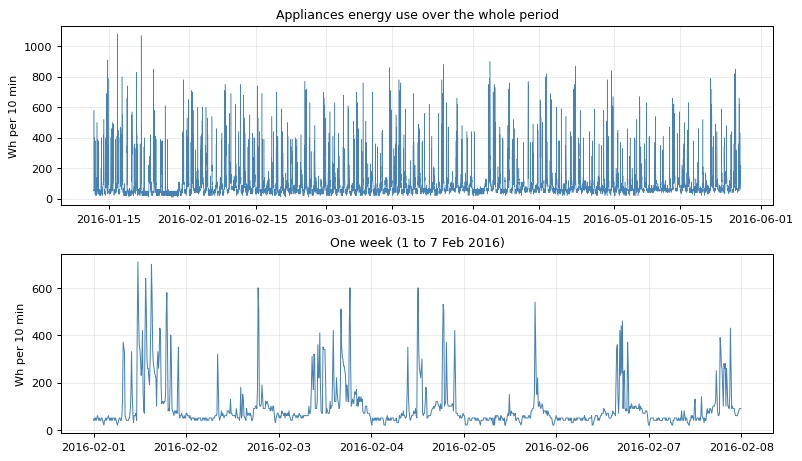

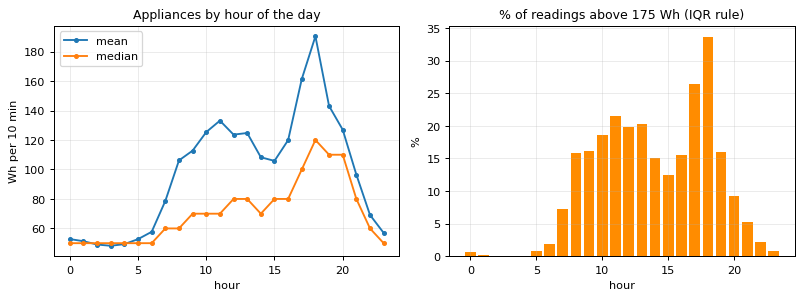

mean by hour: {0: 52.8, 1: 51.3, 2: 49.1, 3: 48.2, 4: 49.4, 5: 52.7, 6: 57.7, 7: 78.6, 8: 106.1, 9: 112.8, 10: 125.4, 11: 133.1, 12: 123.6, 13: 124.7, 14: 108.3, 15: 105.8, 16: 119.9, 17: 161.4, 18: 190.4, 19: 143.1, 20: 127.0, 21: 96.5, 22: 69.1, 23: 57.0}
spike share by hour (%): {0: 0.6, 1: 0.2, 2: 0.0, 3: 0.0, 4: 0.0, 5: 0.9, 6: 1.9, 7: 7.2, 8: 15.8, 9: 16.2, 10: 18.6, 11: 21.5, 12: 19.8, 13: 20.3, 14: 15.1, 15: 12.5, 16: 15.6, 17: 26.4, 18: 33.7, 19: 15.9, 20: 9.2, 21: 5.2, 22: 2.2, 23: 0.9}


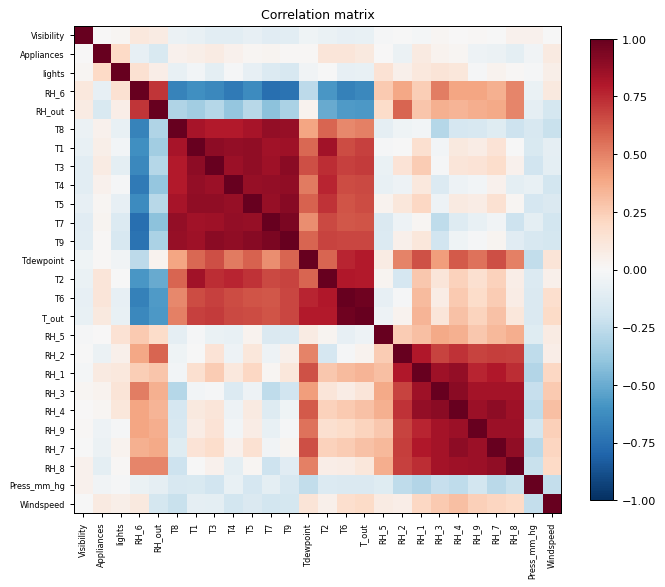

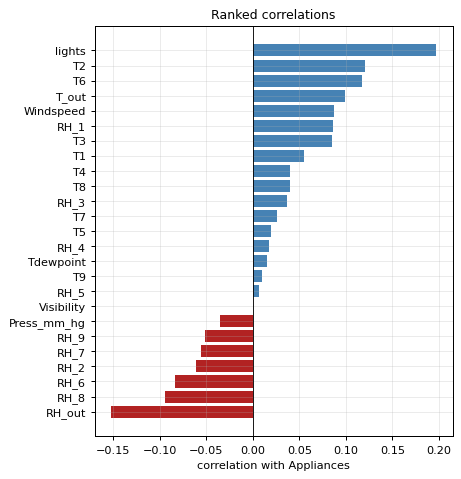

largest |corr| with Appliances: {'lights': 0.197, 'RH_out': 0.152, 'T2': 0.12, 'T6': 0.118, 'T_out': 0.099}
covariate pairs with |corr| > 0.9: [('T3', 'T9', 0.901), ('T5', 'T9', 0.911), ('T6', 'T_out', 0.975), ('T7', 'T9', 0.945)]


In [4]:
y10 = df["Appliances"].values
log("\n==== 1b. EDA ====")
log(f"Appliances: mean={y10.mean():.2f} median={np.median(y10):.1f} sd={y10.std():.2f} "
    f"min={y10.min():.0f} max={y10.max():.0f} skew={skew(y10):.2f} skew(log)={skew(np.log(y10)):.2f}")
q1, q3 = np.quantile(y10, [0.25, 0.75]); fence = q3 + 1.5 * (q3 - q1)
df["spike"] = df["Appliances"] > fence
log(f"IQR rule: Q1={q1:.0f} Q3={q3:.0f} upper fence={fence:.0f}; share above fence = {df['spike'].mean()*100:.1f}%")

# Fig 1: whole series + one week
wk0 = pd.Timestamp("2016-02-01"); wk = (df["date"] >= wk0) & (df["date"] < wk0 + pd.Timedelta(days=7))
fig, ax = plt.subplots(2, 1, figsize=(9, 5.2))
ax[0].plot(df["date"], df["Appliances"], lw=0.4, color="steelblue")
ax[0].set_title("Appliances energy use over the whole period"); ax[0].set_ylabel("Wh per 10 min")
ax[1].plot(df.loc[wk, "date"], df.loc[wk, "Appliances"], lw=0.8, color="steelblue")
ax[1].set_title("One week (1 to 7 Feb 2016)"); ax[1].set_ylabel("Wh per 10 min")
save_fig(fig, "fig01_time_series.png")

# Fig 2: hourly pattern + share of spikes
g = df.groupby("hour")["Appliances"]
spike_share = df.groupby("hour")["spike"].mean() * 100
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
ax[0].plot(g.mean().index, g.mean().values, "o-", label="mean", ms=3)
ax[0].plot(g.median().index, g.median().values, "o-", label="median", ms=3)
ax[0].set_title("Appliances by hour of the day"); ax[0].set_xlabel("hour"); ax[0].set_ylabel("Wh per 10 min"); ax[0].legend()
ax[1].bar(spike_share.index, spike_share.values, color="darkorange")
ax[1].set_title(f"% of readings above {fence:.0f} Wh (IQR rule)"); ax[1].set_xlabel("hour"); ax[1].set_ylabel("%")
save_fig(fig, "fig02_hourly_pattern.png")
log("mean by hour:", g.mean().round(1).to_dict())
log("spike share by hour (%):", spike_share.round(1).to_dict())

# Fig 3: correlation heatmap (clustered order)
cols_all = ["Appliances"] + COVS
C = df[cols_all].corr().values
order = leaves_list(linkage(squareform(1 - np.abs(C), checks=False), "average"))
names_o = [cols_all[i] for i in order]
fig, ax = plt.subplots(figsize=(7.6, 6.6))
im = ax.imshow(C[np.ix_(order, order)], cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(names_o))); ax.set_xticklabels(names_o, rotation=90, fontsize=6.5)
ax.set_yticks(range(len(names_o))); ax.set_yticklabels(names_o, fontsize=6.5)
ax.grid(False); fig.colorbar(im, fraction=0.04); ax.set_title("Correlation matrix")
save_fig(fig, "fig03_corr_heatmap.png")

# Fig 4: ranked correlation with Appliances
cr = df[COVS].corrwith(df["Appliances"]).sort_values()
fig, ax = plt.subplots(figsize=(5.2, 5.4))
ax.barh(cr.index, cr.values, color=np.where(cr.values > 0, "steelblue", "firebrick"))
ax.axvline(0, color="k", lw=0.7); ax.set_xlabel("correlation with Appliances"); ax.set_title("Ranked correlations")
save_fig(fig, "fig04_corr_ranked.png")
save_tab(cr.round(4).to_frame("corr_with_Appliances"), "t03_corr_with_Appliances.csv")
log("largest |corr| with Appliances:", cr.abs().sort_values(ascending=False).head(5).round(3).to_dict())
pairs = [(cols_all[i], cols_all[j], C[i, j]) for i in range(1, len(cols_all)) for j in range(i + 1, len(cols_all)) if abs(C[i, j]) > 0.9]
log("covariate pairs with |corr| > 0.9:", [(a, b, round(c, 3)) for a, b, c in pairs])


VIF on all 10-min data: max=146.8 (T_out), number > 10: 15, number > 5: 20; condition number=50.1


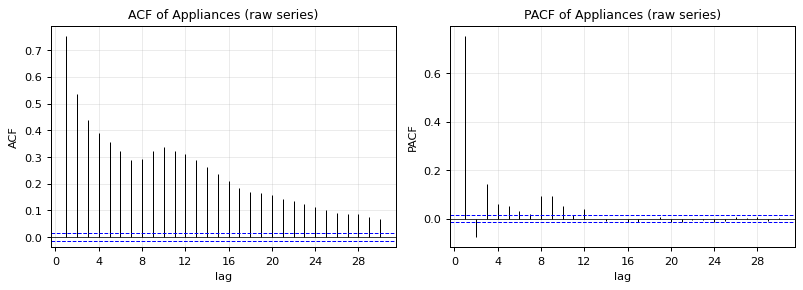

raw ACF: lag1=0.753 lag2=0.534 lag6=0.323 lag30=0.070 lag144 (one day)=0.215


In [5]:
# Fig 5 is made later (VIF 10-minute vs daily). Here: numbers for the 10 minute data.
X10 = df[COVS].values
vif10 = vif_table(X10, COVS)
log(f"\nVIF on all 10-min data: max={vif10.max():.1f} ({vif10.idxmax()}), "
    f"number > 10: {(vif10 > 10).sum()}, number > 5: {(vif10 > 5).sum()}; condition number={cond_number(X10):.1f}")

# Fig 6: ACF / PACF of the raw series
fig, ax = plt.subplots(1, 2, figsize=(9, 3.3))
plot_acf_ax(ax[0], y10, 30, "ACF of Appliances (raw series)")
plot_pacf_ax(ax[1], y10, 30, "PACF of Appliances (raw series)")
save_fig(fig, "fig06_acf_pacf_raw.png")
a_raw = acf(y10, 300)
log(f"raw ACF: lag1={a_raw[1]:.3f} lag2={a_raw[2]:.3f} lag6={a_raw[6]:.3f} lag30={a_raw[30]:.3f} "
    f"lag144 (one day)={a_raw[144]:.3f}")

## 2. Base model (10 minute data, OLS on the 25 covariates)
First 80% of time = training, last 20% = test (we do not shuffle because it is a time series).


==== 2. BASE MODEL ====
train rows=15788 (2016-01-11 17:00:00 to 2016-04-30 08:10:00)
test rows=3947 (2016-04-30 08:20:00 to 2016-05-27 18:00:00)
             estimate  std_error        t  p_value  marginal_corr
Intercept    -67.2949   113.4109  -0.5934   0.5529            NaN
T1            -6.3740     2.2392  -2.8466   0.0044         0.0554
T2           -13.2054     2.0967  -6.2982   0.0000         0.1201
T3            27.7093     1.2436  22.2817   0.0000         0.0851
T4            -3.7953     1.0946  -3.4674   0.0005         0.0403
T5            -1.6752     1.5091  -1.1101   0.2670         0.0198
T6             7.6367     0.8343   9.1531   0.0000         0.1176
T7             1.0760     1.5447   0.6965   0.4861         0.0258
T8             9.0385     1.1059   8.1729   0.0000         0.0396
T9           -14.3506     2.0815  -6.8942   0.0000         0.0100
RH_1          12.8543     0.7583  16.9508   0.0000         0.0860
RH_2         -12.4110     0.9127 -13.5976   0.0000        -0.

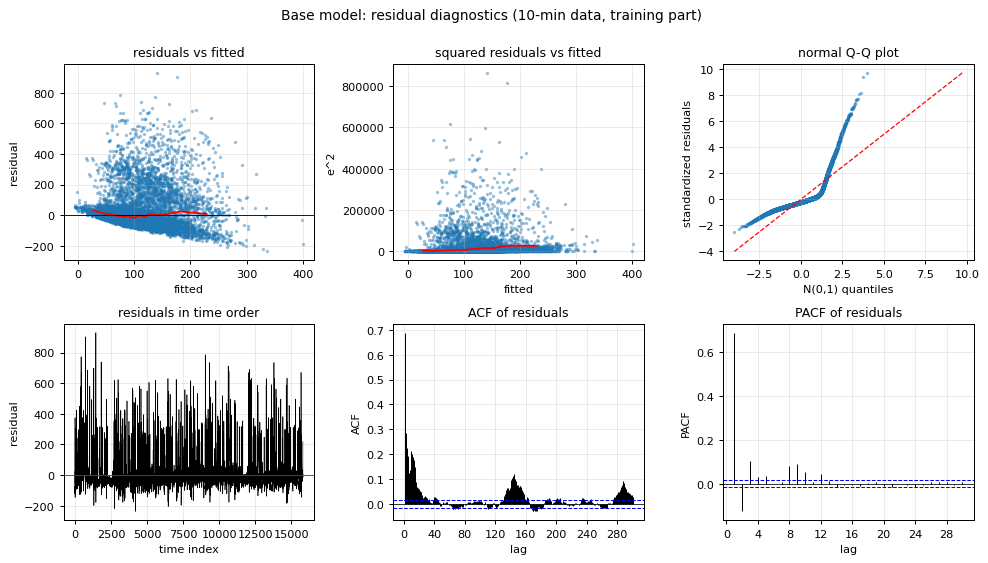

In [6]:
log("\n==== 2. BASE MODEL ====")
n10 = len(df); n_tr = int(np.floor(0.8 * n10))
tr, te = df.iloc[:n_tr], df.iloc[n_tr:]
log(f"train rows={len(tr)} ({tr['date'].min()} to {tr['date'].max()})")
log(f"test rows={len(te)} ({te['date'].min()} to {te['date'].max()})")

base = ols(tr[COVS].values, tr["Appliances"].values)
coef = pd.DataFrame({"estimate": base["beta"], "std_error": base["se"], "t": base["t"], "p_value": base["p"]},
                    index=["Intercept"] + COVS)
coef["marginal_corr"] = [np.nan] + [df[c].corr(df["Appliances"]) for c in COVS]
save_tab(coef.round(4), "t04_base_coefficients.csv")
log(coef.round(4).to_string())
log(f"R2={base['r2']:.4f} adjR2={base['adj']:.4f} F={base['F']:.1f} (p={base['pF']:.2e}) sigma_hat={base['sigma']:.2f}")
flips = [c for c in COVS if (coef.loc[c, "p_value"] < 0.05) and (np.sign(coef.loc[c, "estimate"]) != np.sign(coef.loc[c, "marginal_corr"]))]
log("significant coefficients with sign opposite to marginal correlation:", flips)

bench10 = tr["Appliances"].mean()
pred10 = predict(base["beta"], te[COVS].values); act10 = te["Appliances"].values
base_metrics = pd.DataFrame({"RMSE": [rmse(act10, pred10), rmse(act10, bench10)],
                             "MAE": [mae(act10, pred10), mae(act10, bench10)],
                             "R2_oos": [r2_oos(act10, pred10, bench10), 0.0]},
                            index=["Base OLS (25 covariates)", "Benchmark (training mean)"]).round(3)
save_tab(base_metrics, "t05_base_metrics.csv")
log("\nout of sample, last 20%:\n" + base_metrics.to_string())
log("negative predictions:", int((pred10 < 0).sum()), "of", len(pred10))

d_b, bp_b, cw_b = show_tests("base", base, tr[COVS].values)
resid_panel(base, "Base model: residual diagnostics (10-min data, training part)",
            "fig07_base_residual_panel.png", acf_lags=300)
base_diag = dict(model=base, dw=d_b, bp=bp_b, cw=cw_b, Xtr=tr[COVS].values)

## 3. Method 1: time series (AR) model on the 10 minute series
AR(p): y_t = c + phi_1 y_{t-1} + ... + phi_p y_{t-p} + noise. The order is chosen with AIC (and we look at the PACF).
Same train/test split as the base model.


==== 3. TIME SERIES (AR) ====
AR order chosen by AIC: 14;  by BIC: 12
AR intercept: 13.806  phi (first 5): [ 0.794 -0.179  0.084  0.013  0.026]


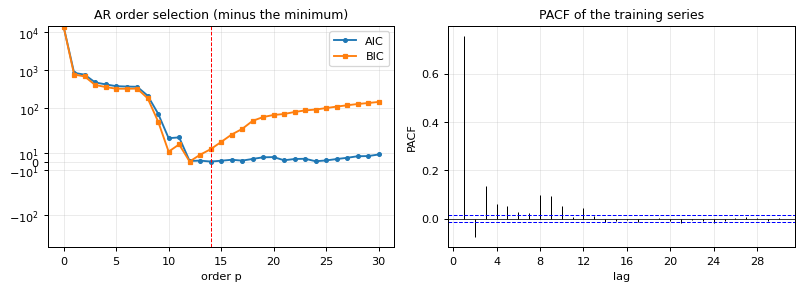


one step ahead, last 20%:
                             RMSE     MAE  R2_oos
AR(14) one step ahead      60.031  26.969   0.565
Naive (previous reading)   66.438  26.651   0.468
Benchmark (training mean)  91.053  52.685   0.000
AR residuals: DW=2.051 lag1 r=-0.026 p=9.93e-02;  ACF at lag 144 = 0.087


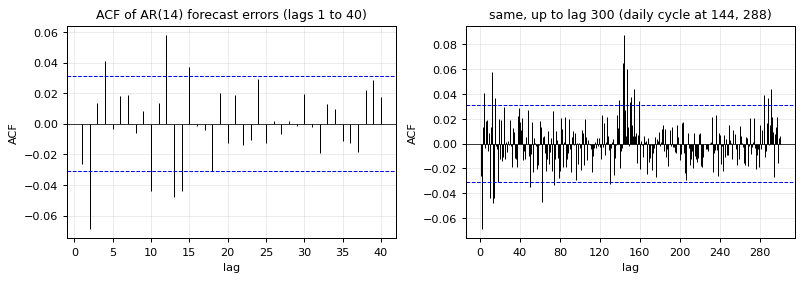

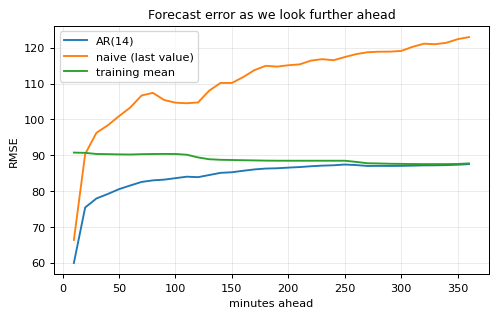

AR RMSE by horizon (10, 30, 60, 120, 240, 360 min): {10: 59.9, 30: 77.9, 60: 81.6, 120: 83.9, 240: 87.2, 360: 87.5}
how far back does the AR model look? 14 readings = 140 minutes


In [7]:
log("\n==== 3. TIME SERIES (AR) ====")
y = df["Appliances"].values.astype(float)
PMAX = 30

def lag_matrix(series, t_idx, p):
    return np.column_stack([series[t_idx - i] for i in range(1, p + 1)])

t_fit = np.arange(PMAX, n_tr)                 # same rows for every order, so AIC is comparable
m_eff = len(t_fit); y_fit = y[t_fit]
aic, bic = [], []
for p in range(0, PMAX + 1):
    if p == 0:
        rss = np.sum((y_fit - y_fit.mean()) ** 2)
    else:
        A = np.column_stack([np.ones(m_eff), lag_matrix(y, t_fit, p)])
        b_ = np.linalg.lstsq(A, y_fit, rcond=None)[0]; rss = np.sum((y_fit - A @ b_) ** 2)
    aic.append(m_eff * np.log(rss / m_eff) + 2 * (p + 1))
    bic.append(m_eff * np.log(rss / m_eff) + np.log(m_eff) * (p + 1))
aic = np.array(aic); bic = np.array(bic)
p_aic = int(np.argmin(aic)); p_bic = int(np.argmin(bic))
log(f"AR order chosen by AIC: {p_aic};  by BIC: {p_bic}")

p_ar = p_aic
t_all = np.arange(p_ar, n_tr)
A = np.column_stack([np.ones(len(t_all)), lag_matrix(y, t_all, p_ar)])
coef_ar = np.linalg.lstsq(A, y[t_all], rcond=None)[0]
c_ar, phi = coef_ar[0], coef_ar[1:]
log("AR intercept:", round(c_ar, 3), " phi (first 5):", np.round(phi[:5], 3))

fig, ax = plt.subplots(1, 2, figsize=(9, 3.3))
ax[0].plot(range(PMAX + 1), aic - aic.min(), "o-", ms=3, label="AIC")
ax[0].plot(range(PMAX + 1), bic - bic.min(), "s-", ms=3, label="BIC")
ax[0].axvline(p_aic, color="r", ls="--", lw=0.8); ax[0].set_yscale("symlog", linthresh=50)
ax[0].set_title("AR order selection (minus the minimum)"); ax[0].set_xlabel("order p"); ax[0].legend()
plot_pacf_ax(ax[1], y[:n_tr], 30, "PACF of the training series")
save_fig(fig, "fig08_ar_order.png")

# one step ahead forecasts on the test part (uses the true previous values)
t_te = np.arange(n_tr, n10)
pred_ar = c_ar + lag_matrix(y, t_te, p_ar) @ phi
pred_naive = y[t_te - 1]
bench_ts = y[:n_tr].mean(); act_ts = y[t_te]
ar_metrics = pd.DataFrame({
    "RMSE": [rmse(act_ts, pred_ar), rmse(act_ts, pred_naive), rmse(act_ts, bench_ts)],
    "MAE": [mae(act_ts, pred_ar), mae(act_ts, pred_naive), mae(act_ts, bench_ts)],
    "R2_oos": [r2_oos(act_ts, pred_ar, bench_ts), r2_oos(act_ts, pred_naive, bench_ts), 0.0]},
    index=[f"AR({p_ar}) one step ahead", "Naive (previous reading)", "Benchmark (training mean)"]).round(3)
save_tab(ar_metrics, "t06_ar_metrics.csv")
log("\none step ahead, last 20%:\n" + ar_metrics.to_string())

# residuals of the AR model
res_ar = act_ts - pred_ar
d_ar = dw_test(res_ar)
log(f"AR residuals: DW={d_ar['D']:.3f} lag1 r={d_ar['r1']:.3f} p={d_ar['p']:.2e};  ACF at lag 144 = {acf(res_ar,150)[144]:.3f}")
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
plot_acf_ax(ax[0], res_ar, 40, f"ACF of AR({p_ar}) forecast errors (lags 1 to 40)")
plot_acf_ax(ax[1], res_ar, 300, "same, up to lag 300 (daily cycle at 144, 288)")
save_fig(fig, "fig10_ar_resid_acf.png")

# multi step ahead: forecasts built from their own forecasts (what we need if we want to look ahead)
H = 36
origins = np.arange(n_tr - 1, n10 - 1 - H)
L = np.column_stack([y[origins - i] for i in range(p_ar)])      # most recent first
rm_ar, rm_naive, rm_mean = [], [], []
for h in range(1, H + 1):
    pr = c_ar + L @ phi
    actual = y[origins + h]
    rm_ar.append(rmse(actual, pr)); rm_naive.append(rmse(actual, y[origins])); rm_mean.append(rmse(actual, bench_ts))
    L = np.column_stack([pr, L[:, :-1]])
fig, ax = plt.subplots(figsize=(5.6, 3.6))
hh = np.arange(1, H + 1) * 10
ax.plot(hh, rm_ar, label=f"AR({p_ar})"); ax.plot(hh, rm_naive, label="naive (last value)"); ax.plot(hh, rm_mean, label="training mean")
ax.set_xlabel("minutes ahead"); ax.set_ylabel("RMSE"); ax.set_title("Forecast error as we look further ahead"); ax.legend()
save_fig(fig, "fig09_ar_horizon.png")
hz = pd.DataFrame({"minutes_ahead": hh, "RMSE_AR": rm_ar, "RMSE_naive": rm_naive, "RMSE_mean": rm_mean}).round(2)
save_tab(hz, "t06b_ar_horizon.csv", index=False)
log("AR RMSE by horizon (10, 30, 60, 120, 240, 360 min):", {int(m): round(v, 1) for m, v in zip(hh, rm_ar) if m in (10, 30, 60, 120, 240, 360)})
log("how far back does the AR model look?", p_ar, "readings =", p_ar * 10, "minutes")

## 4. Method 2: daily averages
Keep only full days (144 readings), take the daily mean of Appliances and of each covariate.


==== 4. DAILY DATA ====
days: 136  first/last day: 2016-01-12 2016-05-26  consecutive: True
daily Appliances: mean=97.40 sd=30.33 min=37.5 max=188.5 skew=0.84 skew(log)=0.03
daily full model (25 covariates): R2=0.5467 adjR2=0.4437

before vs after:
                                10-minute base model  Daily model (full, 25 covariates)
n                                         15788.0000                           136.0000
adjusted R2                                   0.1716                             0.4437
lag-1 residual autocorrelation                0.6886                             0.0764
Durbin-Watson D                               0.6223                             1.8429
DW test p-value                               0.0000                             0.3733
Breusch-Pagan p-value                         0.0000                             0.0085
Cook-Weisberg p-value                         0.0000                             0.0007
residual skewness                             

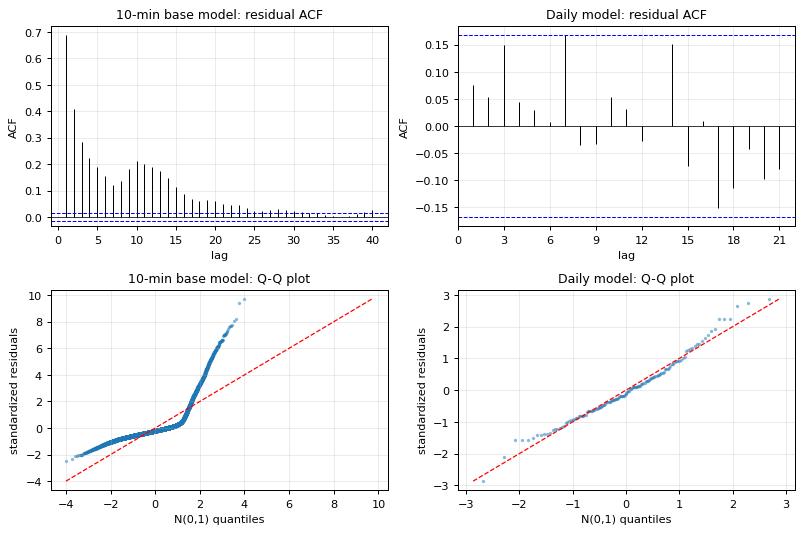

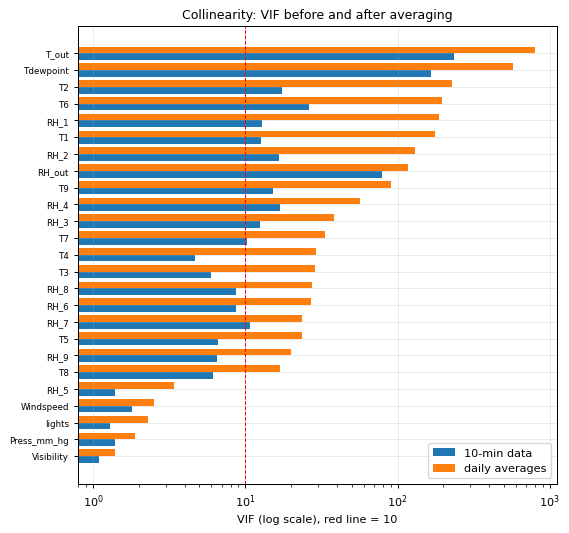

In [8]:
log("\n==== 4. DAILY DATA ====")
dfull = df[df["day"].isin(full_days)].sort_values("date").reset_index(drop=True)
days = np.array(sorted(dfull["day"].unique())); nd = len(days)
daily = dfull.groupby("day")[["Appliances"] + COVS].mean().loc[days]
log("days:", nd, " first/last day:", days[0], days[-1],
    " consecutive:", bool(np.all(np.diff(pd.to_datetime(days).values).astype("timedelta64[D]").astype(int) == 1)))
yd = daily["Appliances"].values; Xd = daily[COVS].values
log(f"daily Appliances: mean={yd.mean():.2f} sd={yd.std(ddof=1):.2f} min={yd.min():.1f} max={yd.max():.1f} "
    f"skew={skew(yd):.2f} skew(log)={skew(np.log(yd)):.2f}")

# tensor of readings: days x 144 slots x covariates (used in the combined model)
R = np.stack([dfull[c].values.reshape(nd, 144) for c in COVS], axis=2)
DM = R.mean(axis=1)
assert np.allclose(DM, Xd)

dfull_model = ols(Xd, yd)
log(f"daily full model (25 covariates): R2={dfull_model['r2']:.4f} adjR2={dfull_model['adj']:.4f}")

# ---- before vs after table (only things from class) ----
def diag_row(m, X, y_resp):
    d, b, c = all_tests(m, X)
    v = vif_table(X, range(X.shape[1]))
    return {"n": m["n"], "adjusted R2": m["adj"], "lag-1 residual autocorrelation": d["r1"],
            "Durbin-Watson D": d["D"], "DW test p-value": d["p"],
            "Breusch-Pagan p-value": b["p"], "Cook-Weisberg p-value": c["p"],
            "residual skewness": skew(m["resid"]), "residual kurtosis": kurt(m["resid"]),
            "skewness of response": skew(y_resp), "skewness of log response": skew(np.log(y_resp)),
            "max VIF": v.max(), "number of VIF > 10": int((v > 10).sum()), "condition number": cond_number(X)}

ba = pd.DataFrame({"10-minute base model": diag_row(base, tr[COVS].values, tr["Appliances"].values),
                   "Daily model (full, 25 covariates)": diag_row(dfull_model, Xd, yd)})
save_tab(ba.round(4), "t07_before_after.csv")
log("\nbefore vs after:\n" + ba.round(4).to_string())
show_tests("daily full", dfull_model, Xd)

# Fig 11: ACF and QQ before vs after
fig, ax = plt.subplots(2, 2, figsize=(9, 6))
plot_acf_ax(ax[0, 0], base["resid"], 40, "10-min base model: residual ACF")
plot_acf_ax(ax[0, 1], dfull_model["resid"], 21, "Daily model: residual ACF")
qq_ax(ax[1, 0], std_resid(base), "10-min base model: Q-Q plot")
qq_ax(ax[1, 1], std_resid(dfull_model), "Daily model: Q-Q plot")
save_fig(fig, "fig11_before_after.png")

# Fig 5: VIF before vs after
vif_d = vif_table(Xd, COVS)
vtab = pd.DataFrame({"VIF_10min": vif_table(tr[COVS].values, COVS), "VIF_daily": vif_d}).round(1)
save_tab(vtab.sort_values("VIF_daily", ascending=False), "t08_vif.csv")
vs = vtab.sort_values("VIF_daily")
fig, ax = plt.subplots(figsize=(6.4, 6))
yy = np.arange(len(vs)); ax.barh(yy - 0.2, vs["VIF_10min"], 0.4, label="10-min data")
ax.barh(yy + 0.2, vs["VIF_daily"], 0.4, label="daily averages")
ax.set_yticks(yy); ax.set_yticklabels(vs.index, fontsize=7); ax.set_xscale("log")
ax.axvline(10, color="r", ls="--", lw=0.8); ax.set_xlabel("VIF (log scale), red line = 10")
ax.set_title("Collinearity: VIF before and after averaging"); ax.legend()
save_fig(fig, "fig05_vif.png")

## 4b. Model building on the daily data

In [9]:
def make_gram(X, y):
    X = np.asarray(X, float); y = np.asarray(y, float)
    mu, sd = X.mean(0), X.std(0); ok = sd > 1e-12
    Z = np.zeros_like(X); Z[:, ok] = (X[:, ok] - mu[ok]) / sd[ok]
    yc = y - y.mean()
    return dict(G=Z.T @ Z, b=Z.T @ yc, sst=float(yc @ yc), n=len(y), K=X.shape[1], ok=ok, Z=Z, yc=yc)

def rss_of(g, S):
    if len(S) == 0: return g["sst"]
    S = list(S); return g["sst"] - g["b"][S] @ np.linalg.solve(g["G"][np.ix_(S, S)], g["b"][S])

def greedy_path(g, direction):
    """returns a list of (subset, rss), sorted by size 0..K"""
    cand = [j for j in range(g["K"]) if g["ok"][j]]
    if direction == "forward":
        S, rem, path = [], cand.copy(), [([], g["sst"])]
        while rem:
            sc = [(rss_of(g, S + [j]), j) for j in rem]; r, j = min(sc)
            S = S + [j]; rem.remove(j); path.append((S.copy(), r))
        return path
    S = cand.copy(); path = [(S.copy(), rss_of(g, S))]
    while S:
        sc = [(rss_of(g, [x for x in S if x != j]), j) for j in S]; r, j = min(sc)
        S = [x for x in S if x != j]; path.append((S.copy(), r))
    return path[::-1]

def criteria(rss, k, n, s2F, sst):
    return dict(adjR2=1 - (rss / (n - k - 1)) / (sst / (n - 1)),
                Cp=rss / s2F + 2 * (k + 1) - n,
                AIC=n * np.log(rss / n) + 2 * (k + 1),
                BIC=n * np.log(rss / n) + np.log(n) * (k + 1))

def loocv_rmse(g, S):
    """PRESS from class notes: mean of (e_i / (1 - h_ii))^2, needs only one fit"""
    n = g["n"]
    if len(S) == 0:
        h = np.full(n, 1 / n); e = g["yc"]
    else:
        S = list(S); Zs = g["Z"][:, S]; Gi = np.linalg.inv(g["G"][np.ix_(S, S)])
        beta = Gi @ g["b"][S]; e = g["yc"] - Zs @ beta; h = 1 / n + np.einsum("ij,jk,ik->i", Zs, Gi, Zs)
    return float(np.sqrt(np.mean((e / (1 - h)) ** 2)))

def pick_best(path, g, crit):
    Kc = len(path[-1][0]); n = g["n"]; s2F = path[-1][1] / (n - Kc - 1)
    vals = []
    for S, r in path:
        k = len(S)
        if crit == "LOOCV": vals.append(loocv_rmse(g, S))
        else:
            if k >= n - 1: vals.append(np.nan); continue
            c = criteria(r, k, n, s2F, g["sst"])[crit]; vals.append(-c if crit == "adjR2" else c)
    vals = np.array(vals); return path[int(np.nanargmin(vals))][0]

def best_subsets(g, kmax, chunk=100000):
    cand = np.array([j for j in range(g["K"]) if g["ok"][j]]); out = {}
    for k in range(1, kmax + 1):
        it = itertools.combinations(cand, k); best = (np.inf, None)
        while True:
            blk = list(itertools.islice(it, chunk))
            if not blk: break
            idx = np.array(blk)
            Gs = g["G"][idx[:, :, None], idx[:, None, :]]; bs = g["b"][idx]
            sol = np.linalg.solve(Gs, bs[:, :, None])[:, :, 0]
            rss = g["sst"] - (bs * sol).sum(1); j = int(rss.argmin())
            if rss[j] < best[0]: best = (float(rss[j]), list(idx[j]))
        out[k] = best
    return out

def ols_subset_predict(Xtr, ytr, Xte, S):
    if len(S) == 0: return np.full(len(Xte), ytr.mean())
    m = ols(Xtr[:, S], ytr); return predict(m["beta"], Xte[:, S])

def select_vars(Xtr, ytr, method, crit):
    g = make_gram(Xtr, ytr); return pick_best(greedy_path(g, method), g, crit)


==== 4b. MODEL BUILDING (all 136 days) ====
all possible regressions up to size 8 took 2s
does stepwise find the best subset of each size?
 k  RSS_best_subset  RSS_forward  RSS_backward  forward_is_best  backward_is_best
 1         114096.0     114096.0      119725.3             True             False
 2          90164.0     104768.9       90164.0            False              True
 3          79146.7      85653.2       83418.4            False             False
 4          75445.7      76172.4       77594.2            False             False
 5          70413.6      72983.9       73167.3            False             False
 6          65711.6      66824.1       65711.6            False              True
 7          61479.3      64298.1       61479.3            False              True
 8          60699.3      60998.8       60699.3            False              True


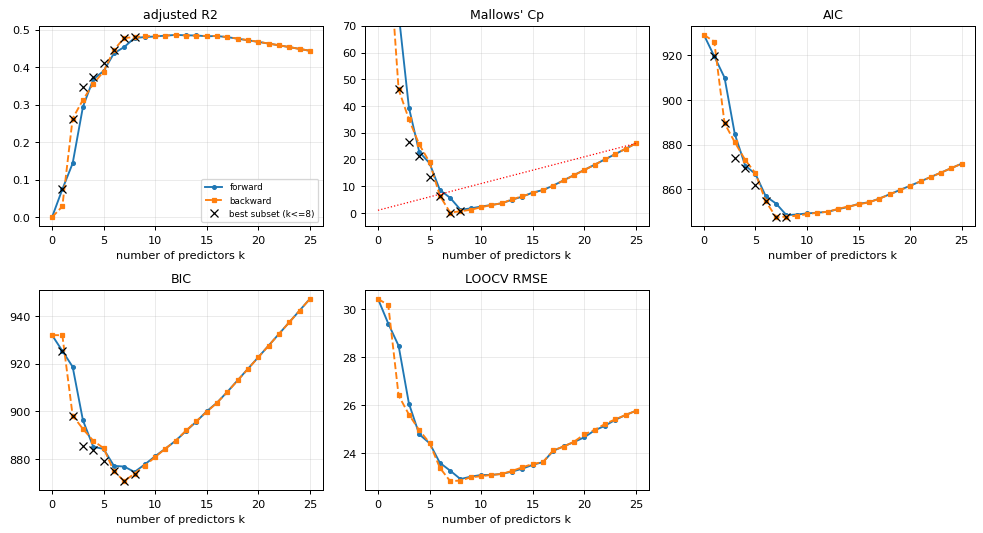


model chosen by each criterion:
  method criterion  size                                                     variables
 forward     adjR2    12 T3, T4, T5, T7, T8, T9, RH_1, RH_2, RH_6, RH_7, T_out, lights
 forward        Cp     8                     T3, T4, T7, T9, RH_1, RH_7, T_out, lights
 forward       AIC     8                     T3, T4, T7, T9, RH_1, RH_7, T_out, lights
 forward       BIC     8                     T3, T4, T7, T9, RH_1, RH_7, T_out, lights
 forward     LOOCV     8                     T3, T4, T7, T9, RH_1, RH_7, T_out, lights
backward     adjR2    12 T3, T4, T5, T7, T8, T9, RH_1, RH_2, RH_6, RH_7, T_out, lights
backward        Cp     7                            T3, T4, T7, T9, RH_1, RH_7, lights
backward       AIC     7                            T3, T4, T7, T9, RH_1, RH_7, lights
backward       BIC     7                            T3, T4, T7, T9, RH_1, RH_7, lights
backward     LOOCV     7                            T3, T4, T7, T9, RH_1, RH_7, lights
BIC of can

In [10]:
log("\n==== 4b. MODEL BUILDING (all 136 days) ====")
gD = make_gram(Xd, yd); nD = gD["n"]
path_f = greedy_path(gD, "forward"); path_b = greedy_path(gD, "backward")
Kc = len(path_b[-1][0]); s2F = path_b[-1][1] / (nD - Kc - 1)

def path_table(path):
    rows = []
    for S, r in path:
        k = len(S); c = criteria(r, k, nD, s2F, gD["sst"]) if k < nD - 1 else {}
        rows.append(dict(k=k, RSS=r, **c, LOOCV_RMSE=loocv_rmse(gD, S)))
    return pd.DataFrame(rows)
tf, tb = path_table(path_f), path_table(path_b)
save_tab(tf.round(3), "t09a_forward_path.csv", index=False); save_tab(tb.round(3), "t09b_backward_path.csv", index=False)

# all possible regressions for sizes 1..8
t0 = time.time(); apr = best_subsets(gD, 8); log(f"all possible regressions up to size 8 took {time.time()-t0:.0f}s")
apr_df = pd.DataFrame([dict(k=k, RSS=v[0], **criteria(v[0], k, nD, s2F, gD["sst"])) for k, v in apr.items()])
chk = pd.DataFrame({"k": range(1, 9),
                    "RSS_best_subset": [apr[k][0] for k in range(1, 9)],
                    "RSS_forward": [tf.loc[tf.k == k, "RSS"].values[0] for k in range(1, 9)],
                    "RSS_backward": [tb.loc[tb.k == k, "RSS"].values[0] for k in range(1, 9)]})
chk["forward_is_best"] = np.isclose(chk.RSS_best_subset, chk.RSS_forward)
chk["backward_is_best"] = np.isclose(chk.RSS_best_subset, chk.RSS_backward)
save_tab(chk.round(2), "t09c_best_subset_check.csv", index=False)
log("does stepwise find the best subset of each size?\n" + chk.round(1).to_string(index=False))

# Fig 13: criteria vs size
fig, ax = plt.subplots(2, 3, figsize=(11, 6))
panels = [("adjR2", "adjusted R2"), ("Cp", "Mallows' Cp"), ("AIC", "AIC"), ("BIC", "BIC"), ("LOOCV_RMSE", "LOOCV RMSE")]
for a, (col, ttl) in zip(ax.ravel(), panels):
    a.plot(tf.k, tf[col], "o-", ms=3, label="forward"); a.plot(tb.k, tb[col], "s--", ms=3, label="backward")
    if col in apr_df.columns: a.plot(apr_df.k, apr_df[col], "kx", ms=6, label="best subset (k<=8)")
    if col == "Cp": a.plot([0, 25], [1, 26], "r:", lw=1, label="Cp = k+1")
    a.set_title(ttl); a.set_xlabel("number of predictors k")
ax[0, 0].legend(fontsize=7); ax[1, 2].axis("off")
ax[0, 1].set_ylim(min(0, tf.Cp.min(), tb.Cp.min()) - 5, 70)     # cut the huge Cp of tiny models so the useful part is visible
save_fig(fig, "fig13_selection_criteria.png")

crit_rows = []
for meth, path in [("forward", path_f), ("backward", path_b)]:
    for crit in ["adjR2", "Cp", "AIC", "BIC", "LOOCV"]:
        S = pick_best(path, gD, crit)
        crit_rows.append(dict(method=meth, criterion=crit, size=len(S), variables=", ".join(COVS[j] for j in sorted(S))))
crit_df = pd.DataFrame(crit_rows); save_tab(crit_df, "t10_selection_summary.csv", index=False)
log("\nmodel chosen by each criterion:\n" + crit_df.to_string(index=False))

# final model = lowest BIC among forward, backward and best subset
cands = {"forward": pick_best(path_f, gD, "BIC"), "backward": pick_best(path_b, gD, "BIC")}
for k, (r, S) in apr.items(): cands[f"best subset k={k}"] = S
cands = {k: v for k, v in cands.items() if len(v) > 0}      # a model with no predictors is not useful as a final model
bic_of = {nm: criteria(rss_of(gD, S), len(S), nD, s2F, gD["sst"])["BIC"] for nm, S in cands.items()}
best_name = min(bic_of, key=bic_of.get)
FINAL = sorted(cands[best_name]); FINAL_NAMES = [COVS[j] for j in FINAL]
log("BIC of candidate models:", {k: round(v, 2) for k, v in bic_of.items()})
log("FINAL model chosen (lowest BIC):", best_name, "->", FINAL_NAMES)
fw_set = sorted(cands["forward"]); log("forward BIC model:", [COVS[j] for j in fw_set],
    " BIC difference vs final =", round(bic_of["forward"] - bic_of[best_name], 2))

## 4c. Box-Cox


==== 4c. BOX-COX ====
Box-Cox lambda_hat=0.16, 95% interval approx [-0.26, 0.56]; contains 0 (log)? True;  contains 1 (no transform)? False
residual skewness raw=0.32, log=-0.15;  BP p raw=0.012, log=0.021


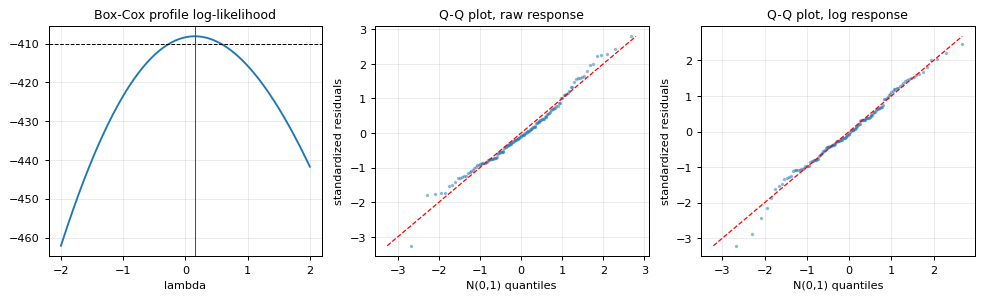

In [11]:
log("\n==== 4c. BOX-COX ====")
Xf = Xd[:, FINAL]
def boxcox_profile(yv, X, lams):
    n = len(yv); out = []
    for lam in lams:
        z = np.log(yv) if abs(lam) < 1e-9 else (yv ** lam - 1) / lam
        m = ols(X, z); out.append(-n / 2 * np.log(m["rss"] / n) + (lam - 1) * np.sum(np.log(yv)))
    return np.array(out)
lams = np.round(np.arange(-2, 2.0001, 0.02), 2)
ll = boxcox_profile(yd, Xf, lams)
lam_hat = float(lams[ll.argmax()]); inside = lams[ll >= ll.max() - 1.92]
log(f"Box-Cox lambda_hat={lam_hat:.2f}, 95% interval approx [{inside.min():.2f}, {inside.max():.2f}]; "
    f"contains 0 (log)? {inside.min() <= 0 <= inside.max()};  contains 1 (no transform)? {inside.min() <= 1 <= inside.max()}")
m_raw = ols(Xf, yd); m_log = ols(Xf, np.log(yd))
log(f"residual skewness raw={skew(m_raw['resid']):.2f}, log={skew(m_log['resid']):.2f};  "
    f"BP p raw={bp_test(m_raw['resid'], Xf)['p']:.3f}, log={bp_test(m_log['resid'], Xf)['p']:.3f}")
fig, ax = plt.subplots(1, 3, figsize=(11, 3.4))
ax[0].plot(lams, ll); ax[0].axhline(ll.max() - 1.92, color="k", ls="--", lw=0.8)
ax[0].axvline(lam_hat, color="r", lw=0.8); ax[0].set_title("Box-Cox profile log-likelihood"); ax[0].set_xlabel("lambda")
qq_ax(ax[1], std_resid(m_raw), "Q-Q plot, raw response"); qq_ax(ax[2], std_resid(m_log), "Q-Q plot, log response")
save_fig(fig, "fig14_boxcox.png")

## 4d. Final model


==== 4d. FINAL DAILY MODEL ====
           estimate  std_error      t  p_value   CI_low  CI_high  std_coef (per 1 sd)
Intercept   -78.203     32.096 -2.437    0.016 -141.710  -14.696               97.396
T3           32.773      3.421  9.580    0.000   26.004   39.542               62.432
T4          -10.813      3.091 -3.498    0.001  -16.930   -4.696              -21.019
T7           18.404      3.911  4.705    0.000   10.665   26.144               37.707
T9          -36.464      5.449 -6.692    0.000  -47.246  -25.683              -72.980
RH_1          3.926      1.322  2.968    0.004    1.309    6.543               14.135
RH_7         -4.509      1.006 -4.483    0.000   -6.500   -2.519              -20.816
lights        2.827      0.716  3.948    0.000    1.410    4.244                8.931
R2=0.5049 adjR2=0.4779 F=18.65 (p=5.70e-17) sigma_hat=21.92
EQUATION (daily means): avg_energy = -78.20 + 32.77*T3 - 10.81*T4 + 18.40*T7 - 36.46*T9 + 3.93*RH_1 - 4.51*RH_7 + 2.83*lights
VIF ins

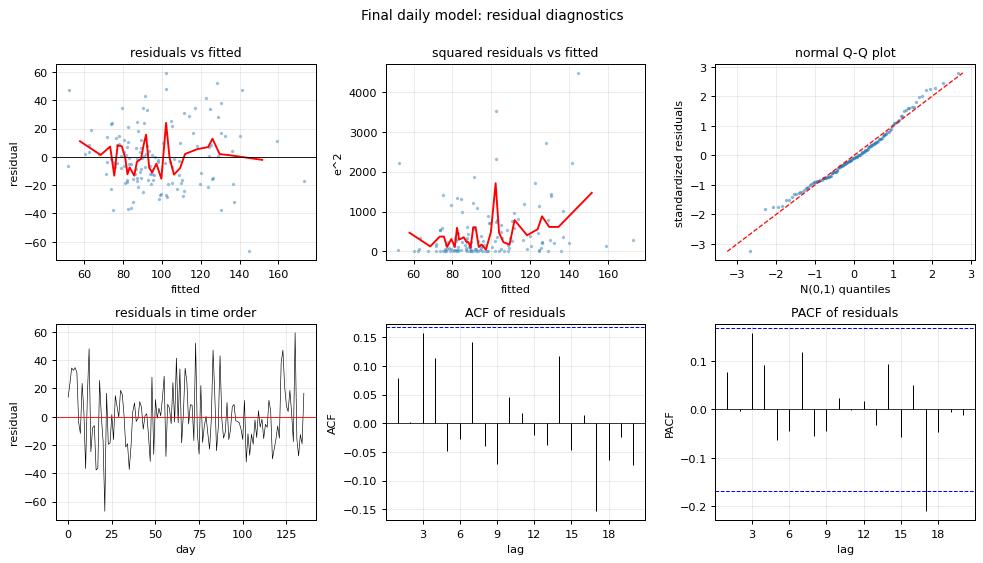

largest cook's-type check: max |standardized residual| = 3.25

WLS check:
              OLS  WLS (var ~ mean^2)
Intercept -78.203             -72.623
T3         32.773              29.059
T4        -10.813              -9.172
T7         18.404              15.190
T9        -36.464             -30.215
RH_1        3.926               2.920
RH_7       -4.509              -3.887
lights      2.827               4.078
Breusch-Pagan p on weighted residuals: 0.414  Cook-Weisberg p: 0.838


In [12]:
log("\n==== 4d. FINAL DAILY MODEL ====")
fin = ols(Xf, yd)
tcrit = stats.t.ppf(0.975, fin["dof"])
ft = pd.DataFrame({"estimate": fin["beta"], "std_error": fin["se"], "t": fin["t"], "p_value": fin["p"],
                   "CI_low": fin["beta"] - tcrit * fin["se"], "CI_high": fin["beta"] + tcrit * fin["se"]},
                  index=["Intercept"] + FINAL_NAMES)
zs = (Xf - Xf.mean(0)) / Xf.std(0, ddof=1); fz = ols(zs, yd)
ft["std_coef (per 1 sd)"] = fz["beta"]
save_tab(ft.round(4), "t11_final_coefficients.csv")
log(ft.round(3).to_string())
log(f"R2={fin['r2']:.4f} adjR2={fin['adj']:.4f} F={fin['F']:.2f} (p={fin['pF']:.2e}) sigma_hat={fin['sigma']:.2f}")
eq = f"avg_energy = {fin['beta'][0]:.2f}" + "".join(f" {'+' if b >= 0 else '-'} {abs(b):.2f}*{nm}" for b, nm in zip(fin["beta"][1:], FINAL_NAMES))
log("EQUATION (daily means):", eq)
vf = vif_table(Xf, FINAL_NAMES); log("VIF inside final model:", vf.round(1).to_dict(), " condition number:", round(cond_number(Xf), 1))
d_f, bp_f, cw_f = show_tests("final", fin, Xf)
resid_panel(fin, "Final daily model: residual diagnostics", "fig15_final_residual_panel.png", acf_lags=20, index_label="day")
log(f"largest cook's-type check: max |standardized residual| = {np.abs(std_resid(fin)).max():.2f}")

# weighted least squares check (class: GLS/WLS, variance depending on the mean, g = (mean)^2)
wls_beta = fin["beta"].copy(); A_ = fin["A"]
for _ in range(15):
    yh = np.maximum(A_ @ wls_beta, 1e-6); w = 1 / yh ** 2
    W = A_.T @ (A_ * w[:, None]); wls_beta = np.linalg.solve(W, A_.T @ (w * yd))
yh = A_ @ wls_beta; e_w = (yd - yh) / yh
wls_tab = pd.DataFrame({"OLS": fin["beta"], "WLS (var ~ mean^2)": wls_beta}, index=["Intercept"] + FINAL_NAMES)
save_tab(wls_tab.round(3), "t12_wls_check.csv"); log("\nWLS check:\n" + wls_tab.round(3).to_string())
log("Breusch-Pagan p on weighted residuals:", round(bp_test(e_w, Xf)["p"], 3), " Cook-Weisberg p:", round(cw_test(e_w, yh)["p"], 3))

## 4e. Evaluation of the daily models
200 random 80/20 splits. 


==== 4e. EVALUATION OF DAILY MODELS ====

200 random 80/20 splits:
              RMSE mean  RMSE sd  MAE mean  R2_oos mean  R2_oos sd  beats benchmark (% of splits)  avg # variables
Benchmark        30.112    3.540    23.525        0.000      0.000                            NaN            0.000
Full OLS         26.079    3.424    20.376        0.210      0.318                           82.5           25.000
Backward AIC     24.888    3.348    19.347        0.285      0.253                           88.5            9.305
Backward BIC     23.931    3.401    18.662        0.339      0.239                           93.0            6.885
Forward BIC      24.949    3.005    19.528        0.283      0.233                           89.5            6.440

paired RMSE differences (negative = first one better):
                             mean_diff     low   high  share_a_better
Backward BIC - Benchmark        -6.181 -12.973  1.875            93.0
Backward BIC - Full OLS         -2.148  -7.034

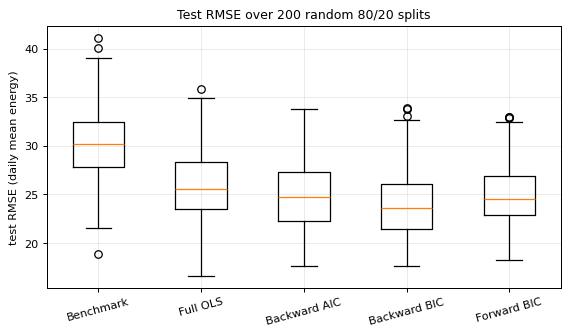


time ordered check (train on early days, test on days 81-136, 56 test days):
                RMSE     MAE  R2_oos
Benchmark     30.876  24.160   0.000
Full OLS      31.405  23.543  -0.035
Backward AIC  28.288  20.721   0.161
Backward BIC  27.620  21.673   0.200
Forward BIC   28.424  21.810   0.152
95% prediction intervals (backward BIC model): coverage=93.8% (sd 4.9), average width=90.5


In [13]:
log("\n==== 4e. EVALUATION OF DAILY MODELS ====")
B = 200; rng = np.random.default_rng(2026); n_train = int(round(0.8 * nd))
models = ["Benchmark", "Full OLS", "Backward AIC", "Backward BIC", "Forward BIC"]

def eval_models(Xtr, ytr, Xte):
    out = {"Benchmark": np.full(len(Xte), ytr.mean()), "Full OLS": ols_subset_predict(Xtr, ytr, Xte, list(range(Xtr.shape[1])))}
    g = make_gram(Xtr, ytr); pb, pf = greedy_path(g, "backward"), greedy_path(g, "forward")
    Sb_aic, Sb_bic, Sf_bic = pick_best(pb, g, "AIC"), pick_best(pb, g, "BIC"), pick_best(pf, g, "BIC")
    out["Backward AIC"] = ols_subset_predict(Xtr, ytr, Xte, sorted(Sb_aic))
    out["Backward BIC"] = ols_subset_predict(Xtr, ytr, Xte, sorted(Sb_bic))
    out["Forward BIC"] = ols_subset_predict(Xtr, ytr, Xte, sorted(Sf_bic))
    return out, dict(bwd_aic=len(Sb_aic), bwd_bic=len(Sb_bic), fwd_bic=len(Sf_bic), sel_bic=sorted(Sb_bic))

store = {m: {"RMSE": [], "MAE": [], "R2": []} for m in models}; sizes = []; sel_count = np.zeros(len(COVS)); splits = []
for b in range(B):
    perm = rng.permutation(nd); tri, tei = np.sort(perm[:n_train]), np.sort(perm[n_train:]); splits.append((tri, tei))
    preds, info = eval_models(Xd[tri], yd[tri], Xd[tei]); bench = yd[tri].mean()
    for m in models:
        store[m]["RMSE"].append(rmse(yd[tei], preds[m])); store[m]["MAE"].append(mae(yd[tei], preds[m]))
        store[m]["R2"].append(r2_oos(yd[tei], preds[m], bench))
    sizes.append((info["bwd_aic"], info["bwd_bic"], info["fwd_bic"]))
    for j in info["sel_bic"]: sel_count[j] += 1
sizes = np.array(sizes)

ev = pd.DataFrame({m: {"RMSE mean": np.mean(store[m]["RMSE"]), "RMSE sd": np.std(store[m]["RMSE"], ddof=1),
                       "MAE mean": np.mean(store[m]["MAE"]), "R2_oos mean": np.mean(store[m]["R2"]),
                       "R2_oos sd": np.std(store[m]["R2"], ddof=1),
                       "beats benchmark (% of splits)": 100 * np.mean(np.array(store[m]["RMSE"]) < np.array(store["Benchmark"]["RMSE"]))}
                   for m in models}).T.round(3)
ev["avg # variables"] = [0, 25, sizes[:, 0].mean(), sizes[:, 1].mean(), sizes[:, 2].mean()]
ev.loc["Benchmark", "beats benchmark (% of splits)"] = np.nan
save_tab(ev, "t13_split_evaluation.csv"); log("\n200 random 80/20 splits:\n" + ev.to_string())

def paired(a, b):
    d = np.array(a) - np.array(b); return dict(mean_diff=d.mean(), low=np.quantile(d, 0.025), high=np.quantile(d, 0.975), share_a_better=np.mean(d < 0) * 100)
pr = pd.DataFrame({"Backward BIC - Benchmark": paired(store["Backward BIC"]["RMSE"], store["Benchmark"]["RMSE"]),
                   "Backward BIC - Full OLS": paired(store["Backward BIC"]["RMSE"], store["Full OLS"]["RMSE"]),
                   "Backward BIC - Backward AIC": paired(store["Backward BIC"]["RMSE"], store["Backward AIC"]["RMSE"]),
                   "Backward BIC - Forward BIC": paired(store["Backward BIC"]["RMSE"], store["Forward BIC"]["RMSE"])}).T.round(3)
save_tab(pr, "t14_paired_differences.csv"); log("\npaired RMSE differences (negative = first one better):\n" + pr.to_string())
sel = pd.Series(sel_count / B * 100, index=COVS).sort_values(ascending=False).round(1)
save_tab(sel.to_frame("% of splits selected by backward BIC"), "t15_selection_frequency.csv")
log("\nhow often each variable is picked by backward BIC (% of splits):", sel.head(12).to_dict())

fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.boxplot([store[m]["RMSE"] for m in models]); ax.set_xticklabels(models); ax.set_ylabel("test RMSE (daily mean energy)")
ax.set_title("Test RMSE over 200 random 80/20 splits"); plt.setp(ax.get_xticklabels(), rotation=15)
save_fig(fig, "fig16_split_rmse.png")

# time ordered check (rolling origin: train on days before s, test on the next 7 days)
roll = {m: [] for m in models}; roll_bench = []; roll_act = []
for s in range(80, nd, 7):
    te_i = np.arange(s, min(s + 7, nd)); pr_, _ = eval_models(Xd[:s], yd[:s], Xd[te_i])
    for m in models: roll[m].extend(pr_[m])
    roll_act.extend(yd[te_i]); roll_bench.extend([yd[:s].mean()] * len(te_i))
roll_act = np.array(roll_act); roll_bench = np.array(roll_bench)
rt = pd.DataFrame({m: {"RMSE": rmse(roll_act, np.array(roll[m])), "MAE": mae(roll_act, np.array(roll[m])),
                       "R2_oos": r2_oos(roll_act, np.array(roll[m]), roll_bench)} for m in models}).T.round(3)
save_tab(rt, "t16_time_ordered_check.csv")
log(f"\ntime ordered check (train on early days, test on days 81-{nd}, {len(roll_act)} test days):\n" + rt.to_string())

# 95% prediction intervals for the final-type model (coverage on the splits)
cov, wid = [], []
for tri, tei in splits[:B]:
    g = make_gram(Xd[tri], yd[tri]); S = sorted(pick_best(greedy_path(g, "backward"), g, "BIC"))
    m_ = ols(Xd[tri][:, S], yd[tri]); A_te = np.column_stack([np.ones(len(tei)), Xd[tei][:, S]])
    se_p = m_["sigma"] * np.sqrt(1 + np.einsum("ij,jk,ik->i", A_te, m_["AtAi"], A_te))
    ph = A_te @ m_["beta"]; tc = stats.t.ppf(0.975, m_["dof"])
    cov.append(np.mean((yd[tei] >= ph - tc * se_p) & (yd[tei] <= ph + tc * se_p))); wid.append(np.mean(2 * tc * se_p))
log(f"95% prediction intervals (backward BIC model): coverage={np.mean(cov)*100:.1f}% (sd {np.std(cov)*100:.1f}), average width={np.mean(wid):.1f}")

## 5. Combined model: one reading per day
Idea: the house reports all covariates at one fixed time (3 pm, 6 pm or 9 pm).
Step 1: from that reading estimate the daily average of each covariate (simple straight line, learned on training days).
Step 2: put the estimated averages in the daily model and predict the daily mean energy.
Model A = the daily model fitted on the TRUE daily averages, then fed the estimates (this is the idea we described).
Model B = same variable selection but fitted on the estimated averages (the model learns from the same kind of input it will get).
Selection is again done inside the training days in every split.


==== 5. COMBINED MODEL ====

combined model, 200 splits:
                                    RMSE mean  RMSE sd  R2_oos  beats benchmark (%)
Benchmark (training mean)              30.112    3.540   0.000                  NaN
True daily averages (all-day data)     23.931    3.401   0.339                 93.0
15:00 reading, model A                 28.562    3.856   0.033                 58.0
15:00 reading, model B                 24.152    2.742   0.334                 95.0
18:00 reading, model A                 26.685    4.161   0.155                 75.0
18:00 reading, model B                 18.992    2.789   0.580                 99.0
21:00 reading, model A                 24.020    3.642   0.320                 92.0
21:00 reading, model B                 21.778    2.744   0.446                 97.0

paired RMSE differences between reading times (negative = first time better):
                        mean_diff     low   high  share_a_better
model B: 21:00 - 18:00      2.786  -2.215 

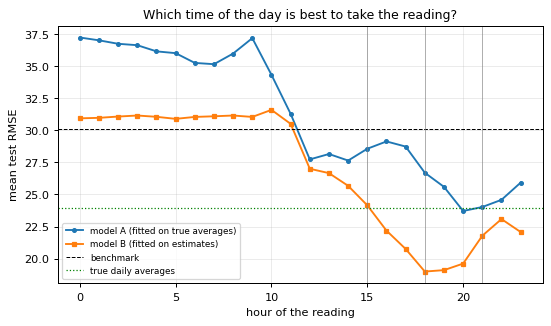


stage 1: R2 between the reading and the daily average of the same variable:
             15:00  18:00  21:00
T1           0.925  0.899  0.851
T2           0.895  0.907  0.833
T3           0.924  0.898  0.924
T4           0.953  0.928  0.900
T5           0.980  0.946  0.820
T6           0.912  0.884  0.873
T7           0.938  0.937  0.968
T8           0.914  0.916  0.935
T9           0.996  0.994  0.989
RH_1         0.881  0.725  0.837
RH_2         0.787  0.827  0.813
RH_3         0.926  0.917  0.850
RH_4         0.947  0.913  0.858
RH_5         0.416  0.322  0.180
RH_6         0.922  0.945  0.936
RH_7         0.911  0.856  0.819
RH_8         0.909  0.846  0.800
RH_9         0.914  0.872  0.800
T_out        0.897  0.888  0.902
Press_mm_hg  0.971  0.945  0.901
RH_out       0.754  0.747  0.707
Windspeed    0.727  0.493  0.486
Visibility   0.020  0.016  0.250
Tdewpoint    0.889  0.847  0.843
lights       0.293  0.221  0.382


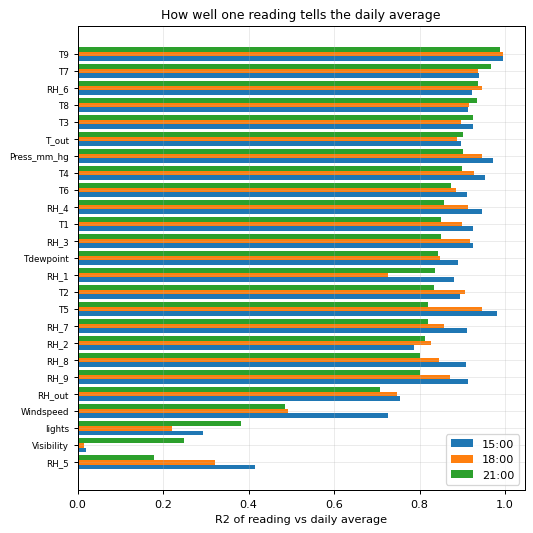

In [14]:
log("\n==== 5. COMBINED MODEL ====")
HOURS = list(range(24)); show_hours = [15, 18, 21]

def stage1(Xh, DM_, tr_idx):
    """straight line from the reading to the daily average, learned on training days only"""
    est = np.zeros_like(Xh)
    for j in range(Xh.shape[1]):
        x, t = Xh[tr_idx, j], DM_[tr_idx, j]; vx = x.var()
        b = ((x - x.mean()) * (t - t.mean())).mean() / vx if vx > 1e-12 else 0.0
        est[:, j] = t.mean() + b * (Xh[:, j] - x.mean())
    return est

resA = {h: [] for h in HOURS}; resB = {h: [] for h in HOURS}; resRef = []; resBench = []
for bi, (tri, tei) in enumerate(splits):
    ytr, yte = yd[tri], yd[tei]; bench = ytr.mean(); resBench.append(rmse(yte, bench))
    g = make_gram(DM[tri], ytr); SA = sorted(pick_best(greedy_path(g, "backward"), g, "BIC"))   # selection on true averages
    mA = ols(DM[tri][:, SA], ytr); resRef.append(rmse(yte, predict(mA["beta"], DM[tei][:, SA])))
    for h in HOURS:
        Xh = R[:, h * 6, :]                                    # reading at hour h:00
        est = stage1(Xh, DM, tri)
        resA[h].append(rmse(yte, predict(mA["beta"], est[tei][:, SA])))
        gB = make_gram(est[tri], ytr); SB = sorted(pick_best(greedy_path(gB, "backward"), gB, "BIC"))
        mB = ols(est[tri][:, SB], ytr); resB[h].append(rmse(yte, predict(mB["beta"], est[tei][:, SB])))
resBench = np.array(resBench); resRef = np.array(resRef)

def r2_from_rmse(rm): return float(np.mean(1 - (np.array(rm) / resBench) ** 2))
rows = [("Benchmark (training mean)", resBench, None), ("True daily averages (all day data)", resRef, None)]
tab = pd.DataFrame({"RMSE mean": [resBench.mean(), resRef.mean()], "RMSE sd": [resBench.std(ddof=1), resRef.std(ddof=1)],
                    "R2_oos": [0.0, r2_from_rmse(resRef)],
                    "beats benchmark (%)": [np.nan, 100 * np.mean(resRef < resBench)]},
                   index=["Benchmark (training mean)", "True daily averages (all-day data)"])
for h in show_hours:
    for nm, res_ in [("A", resA[h]), ("B", resB[h])]:
        rr = np.array(res_)
        tab.loc[f"{h}:00 reading, model {nm}"] = [rr.mean(), rr.std(ddof=1), r2_from_rmse(rr), 100 * np.mean(rr < resBench)]
save_tab(tab.round(3), "t17_combined_model.csv"); log("\ncombined model, 200 splits:\n" + tab.round(3).to_string())

# paired comparison of the reading times (model B and model A)
pt = {}
for nm, resX in [("B", resB), ("A", resA)]:
    for h1, h2 in [(21, 18), (21, 15), (18, 15)]:
        pt[f"model {nm}: {h1}:00 - {h2}:00"] = paired(resX[h1], resX[h2])
pt = pd.DataFrame(pt).T.round(3); save_tab(pt, "t18_reading_time_paired.csv")
log("\npaired RMSE differences between reading times (negative = first time better):\n" + pt.to_string())

# curve over all 24 hours
curve = pd.DataFrame({"hour": HOURS, "RMSE_A": [np.mean(resA[h]) for h in HOURS], "RMSE_B": [np.mean(resB[h]) for h in HOURS]}).round(2)
save_tab(curve, "t19_rmse_by_hour.csv", index=False); log("\nRMSE by reading hour:\n" + curve.to_string(index=False))
fig, ax = plt.subplots(figsize=(6.2, 3.7))
ax.plot(HOURS, curve.RMSE_A, "o-", ms=3, label="model A (fitted on true averages)")
ax.plot(HOURS, curve.RMSE_B, "s-", ms=3, label="model B (fitted on estimates)")
ax.axhline(resBench.mean(), color="k", ls="--", lw=0.8, label="benchmark"); ax.axhline(resRef.mean(), color="g", ls=":", lw=1, label="true daily averages")
for h in show_hours: ax.axvline(h, color="grey", lw=0.5)
ax.set_xlabel("hour of the reading"); ax.set_ylabel("mean test RMSE"); ax.set_title("Which time of the day is best to take the reading?"); ax.legend(fontsize=7)
save_fig(fig, "fig18_rmse_by_hour.png")

# how well can one reading recover the daily average? (corr^2 of reading with the daily mean)
s1 = pd.DataFrame({f"{h}:00": [np.corrcoef(R[:, h * 6, j], DM[:, j])[0, 1] ** 2 if R[:, h * 6, j].std() > 0 else 0 for j in range(len(COVS))]
                   for h in show_hours}, index=COVS).round(3)
save_tab(s1, "t20_stage1_r2.csv"); log("\nstage 1: R2 between the reading and the daily average of the same variable:\n" + s1.to_string())
s1s = s1.sort_values("21:00")
fig, ax = plt.subplots(figsize=(6, 6)); yy = np.arange(len(s1s))
for k, c in enumerate(s1s.columns): ax.barh(yy + (k - 1) * 0.27, s1s[c], 0.27, label=c)
ax.set_yticks(yy); ax.set_yticklabels(s1s.index, fontsize=7); ax.set_xlabel("R2 of reading vs daily average"); ax.legend()
ax.set_title("How well one reading tells the daily average"); save_fig(fig, "fig17_stage1_r2.png")

In [15]:
log(f"\nAll done in {time.time()-t_start:.0f} seconds.")
log("Files saved in:", OUT)
log(sorted(os.listdir(OUT)))


All done in 227 seconds.
Files saved in: /Users/aklantaborah/Desktop/RTProject2/RTimages
['fig01_time_series.png', 'fig02_hourly_pattern.png', 'fig03_corr_heatmap.png', 'fig04_corr_ranked.png', 'fig05_vif.png', 'fig06_acf_pacf_raw.png', 'fig07_base_residual_panel.png', 'fig08_ar_order.png', 'fig09_ar_horizon.png', 'fig10_ar_resid_acf.png', 'fig11_before_after.png', 'fig13_selection_criteria.png', 'fig14_boxcox.png', 'fig15_final_residual_panel.png', 'fig16_split_rmse.png', 'fig17_stage1_r2.png', 'fig18_rmse_by_hour.png', 'results_log.txt', 't01_data_summary.csv', 't02_rv_correlation.csv', 't03_corr_with_Appliances.csv', 't04_base_coefficients.csv', 't05_base_metrics.csv', 't06_ar_metrics.csv', 't06b_ar_horizon.csv', 't07_before_after.csv', 't08_vif.csv', 't09a_forward_path.csv', 't09b_backward_path.csv', 't09c_best_subset_check.csv', 't10_selection_summary.csv', 't11_final_coefficients.csv', 't12_wls_check.csv', 't13_split_evaluation.csv', 't14_paired_differences.csv', 't15_selection_